# Setting

In [1]:
# %pip install scipy
# %pip install mediapipe
# %pip install opencv-python
# %pip install jupyter
# %pip install pandas
# %pip install numpy
# %pip install matplotlib


import os
import glob
import pandas as pd
import numpy as np
import scipy
import matplotlib.pyplot as plt

In [2]:
curfolder = os.getcwd()
print(curfolder)

mtfolder = curfolder + '/Output_TimeSeries/'
print(mtfolder)

processedfolder = curfolder + '/TS_processed/'
vidfolder = curfolder + '/Output_Videos/'

# get all the files in the folder
bodyfiles = glob.glob(mtfolder + '*body_world.csv')
# keep only those tha have GP in the name
#bodyfiles = [x for x in bodyfiles if 'GP' in x]
print(bodyfiles)
handfiles = glob.glob(mtfolder + '*hands_world.csv')
# keep only those tha have GP in the name
handfiles = [x for x in handfiles if 'GP' in x]
facefiles = glob.glob(mtfolder + '*face_world.csv')
# keep only those tha have GP in the name
facefiles = [x for x in facefiles if 'GP' in x]

vidfiles = glob.glob(vidfolder + '*.mp4')
print(vidfiles)

/Users/door/Desktop/GtST_FLESH_KinTrajectory/MotionTracking
/Users/door/Desktop/GtST_FLESH_KinTrajectory/MotionTracking/Output_TimeSeries/
['/Users/door/Desktop/GtST_FLESH_KinTrajectory/MotionTracking/Output_TimeSeries/LP29_02_MOND.mp4_body_world.csv', '/Users/door/Desktop/GtST_FLESH_KinTrajectory/MotionTracking/Output_TimeSeries/LP08_01_EI.mp4_body_world.csv', '/Users/door/Desktop/GtST_FLESH_KinTrajectory/MotionTracking/Output_TimeSeries/LP42_01_AUSRADIEREN.mp4_body_world.csv', '/Users/door/Desktop/GtST_FLESH_KinTrajectory/MotionTracking/Output_TimeSeries/LP36_01_LAPTOP.mp4_body_world.csv', '/Users/door/Desktop/GtST_FLESH_KinTrajectory/MotionTracking/Output_TimeSeries/LP33_01_HAARE.mp4_body_world.csv', '/Users/door/Desktop/GtST_FLESH_KinTrajectory/MotionTracking/Output_TimeSeries/LP18_01_ZAUN.mp4_body_world.csv', '/Users/door/Desktop/GtST_FLESH_KinTrajectory/MotionTracking/Output_TimeSeries/LP08_01_KLAVIER.mp4_body_world.csv', '/Users/door/Desktop/GtST_FLESH_KinTrajectory/MotionTracki

# Preps

## Clean the data

In [4]:
file = bodyfiles[0]
# get the last part of the path in sample
def clean_data(file):
    sample = pd.read_csv(file)
    sample
    fileID = os.path.basename(file)
    print(fileID)

    # replace _body.csv with ''
    fileID = fileID.replace('.mp4', '')
    fileID = fileID.replace('.csv', '')
    print(fileID)

    # add fileID column to the sample
    sample['fileID'] = fileID

    # in the sample, get rid of all columns that contain visibility
    visibility_columns = [col for col in sample.columns if 'visibility' in col]

    # get rid of all columns that contain visibility
    sample = sample.drop(visibility_columns, axis=1)

    # for body - lowbody columns
    lowbody = ['FOOT', 'HEEL', 'ANKLE', 'KEE']
    sample = sample.drop([col for col in sample.columns if any(x in col for x in lowbody)], axis=1)


    return sample

sample = clean_data(file)

GP01_PRUEFUNG.mp4_body_world.csv
GP01_PRUEFUNG_body_world


## Flip the Y axis vertical data

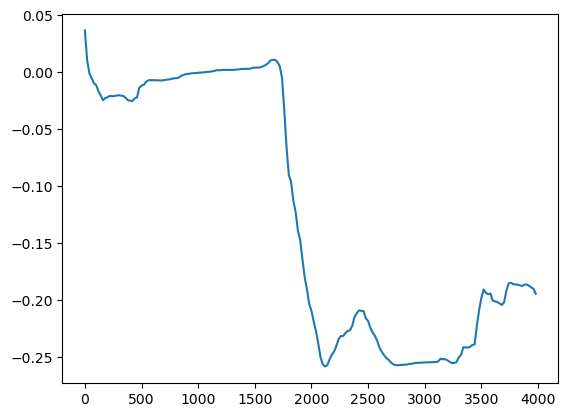

C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_26568\2572589367.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[joint][frame] = ytrans
C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_26568\2572589367.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[joint][frame] = ytrans
C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_26568\2572589367.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[joint][frame] = ytran

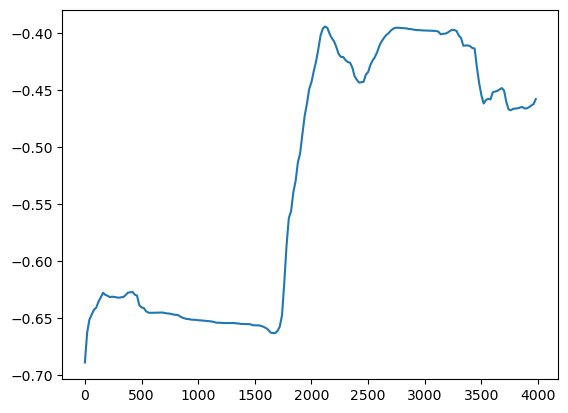

In [5]:
# plot left wrist, vertical (pre flipping)

plt.plot(sample['time'], sample['Y_LEFT_WRIST'])
plt.show()

# flip the y-axis data (code modified from envisionbox)
def flip_data(df):
    cols = df.columns
    cols  = [col for col in df.columns if 'Y_' in col]
    cols = list(cols)
        # first get the vertical height of the configuration
        # we only do this for the first frame; the transformation will be applied to all frames
    maxpoint = []
    for joint in cols:
        maxpoint.append(df[joint][0])
        # iterate over each joint, in each frame, to flip the y-axis
    for frame in range(len(df)):
        for joint in cols:
            ytrans = max(maxpoint) - df[joint][frame] - 1
            df[joint][frame] = ytrans
 
    return df

sample = flip_data(sample)

# plot left wrist, vertical (post flipping)

plt.plot(sample['time'], sample['Y_LEFT_WRIST'])
plt.show()

## Interpolate the data

In [7]:
# obtain column names
def interpolate(sample):
    cols = sample.columns
    print(cols)

# put away time and fileID from cols
    cols = cols.drop(['time', 'fileID'])

# loop over the cols and interpolate missing data
    for col in cols:
        sample[col] = sample[col].interpolate(method='linear', x = sample['time'], limit=10)
    return cols, sample

cols, sample = interpolate(sample)

Index(['time', 'X_NOSE', 'Y_NOSE', 'Z_NOSE', 'X_LEFT_EYE_INNER',
       'Y_LEFT_EYE_INNER', 'Z_LEFT_EYE_INNER', 'X_LEFT_EYE', 'Y_LEFT_EYE',
       'Z_LEFT_EYE', 'X_LEFT_EYE_OUTER', 'Y_LEFT_EYE_OUTER',
       'Z_LEFT_EYE_OUTER', 'X_RIGHT_EYE_OUTER', 'Y_RIGHT_EYE_OUTER',
       'Z_RIGHT_EYE_OUTER', 'X_RIGHT_EYE', 'Y_RIGHT_EYE', 'Z_RIGHT_EYE',
       'X_RIGHT_EYE_OUTER.1', 'Y_RIGHT_EYE_OUTER.1', 'Z_RIGHT_EYE_OUTER.1',
       'X_LEFT_EAR', 'Y_LEFT_EAR', 'Z_LEFT_EAR', 'X_RIGHT_EAR', 'Y_RIGHT_EAR',
       'Z_RIGHT_EAR', 'X_MOUTH_LEFT', 'Y_MOUTH_LEFT', 'Z_MOUTH_LEFT',
       'X_MOUTH_RIGHT', 'Y_MOUTH_RIGHT', 'Z_MOUTH_RIGHT', 'X_LEFT_SHOULDER',
       'Y_LEFT_SHOULDER', 'Z_LEFT_SHOULDER', 'X_RIGHT_SHOULDER',
       'Y_RIGHT_SHOULDER', 'Z_RIGHT_SHOULDER', 'X_LEFT_ELBOW', 'Y_LEFT_ELBOW',
       'Z_LEFT_ELBOW', 'X_RIGHT_ELBOW', 'Y_RIGHT_ELBOW', 'Z_RIGHT_ELBOW',
       'X_LEFT_WRIST', 'Y_LEFT_WRIST', 'Z_LEFT_WRIST', 'X_RIGHT_WRIST',
       'Y_RIGHT_WRIST', 'Z_RIGHT_WRIST', 'X_LEFT_PINKY', 'Y_LEFT_

## Smooth the data

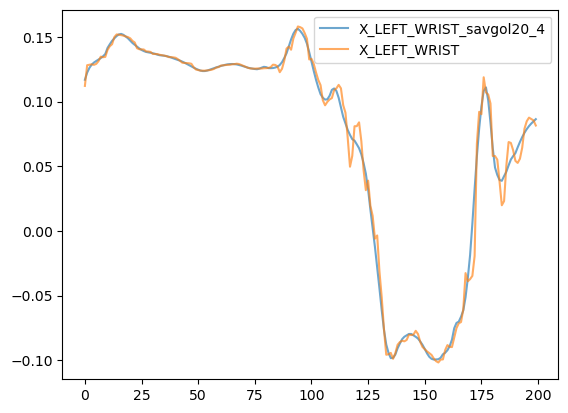

In [8]:
# test the different smoothing filter options - smoothing with savitzky-golay filter
x = 'X_LEFT_WRIST'
z = 'Z_LEFT_WRIST'
y = 'Y_LEFT_WRIST'


# list possible window
window = [20]
# list possible orders
order = [4]

# col of interest
samplecol = [y, z, x]

# iterate over handcols and apply all possible combinations of window and order, save it to new df
# prepare new df
df_smooth = pd.DataFrame()

for col in samplecol:
    for win in window:
        for ord in order:
            df_smooth[col + '_savgol' + str(win) + '_' + str(ord)] = scipy.signal.savgol_filter(sample[col], win, ord)


# make R_Hand_x from df_sample a list
LKnee_x = sample[x].tolist()
LKnee_y = sample[y].tolist()
LKnee_z = sample[z].tolist()


# load these values into df_smooth as a new column
df_smooth[x] = LKnee_x
df_smooth[y] = LKnee_y
df_smooth[z] = LKnee_z

#plot all R_Hand_x columns in one plot
colstoplot = [col for col in df_smooth.columns if x in col]
for col in colstoplot:
    plt.plot(df_smooth[col], label=col, alpha=0.65)
plt.legend()
# make only timewindow 50 to 250
#plt.xlim(100, 200)
#plt.ylim(.0529,.0535)
plt.show()

# sarka's notes
### 15, 1 seems quite solid

# but for lower body let's try 20,1


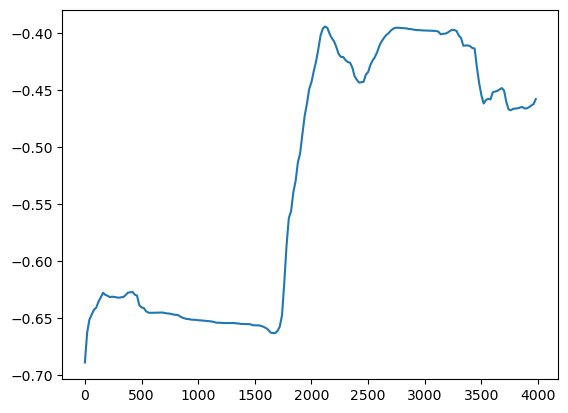

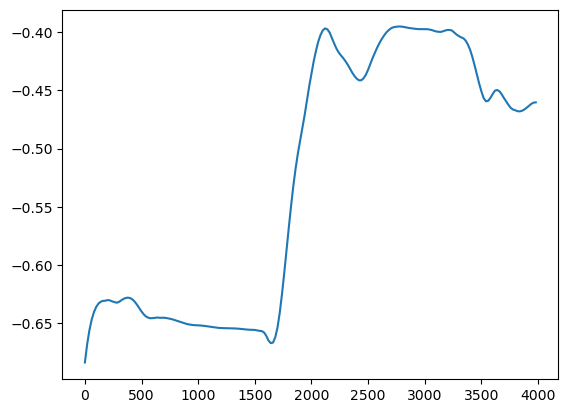

In [9]:
# obtain separate lists of the columns for the upper and lower body (face is included in upper body)

def smooth_data(sample):
    
    if 'body' in sample['fileID'][0]:

        cols_upperbody = ['X_NOSE', 'Y_NOSE', 'Z_NOSE', 'X_LEFT_EYE_INNER', 'Y_LEFT_EYE_INNER', 'Z_LEFT_EYE_INNER', 'X_LEFT_EYE', 'Y_LEFT_EYE', 'Z_LEFT_EYE', 'X_LEFT_EYE_OUTER', 'Y_LEFT_EYE_OUTER', 'Z_LEFT_EYE_OUTER', 'X_RIGHT_EYE_OUTER', 'Y_RIGHT_EYE_OUTER', 'Z_RIGHT_EYE_OUTER', 'X_RIGHT_EYE', 'Y_RIGHT_EYE', 'Z_RIGHT_EYE', 'X_RIGHT_EYE_OUTER.1', 'Y_RIGHT_EYE_OUTER.1', 'Z_RIGHT_EYE_OUTER.1', 'X_LEFT_EAR', 'Y_LEFT_EAR', 'Z_LEFT_EAR', 'X_RIGHT_EAR', 'Y_RIGHT_EAR', 'Z_RIGHT_EAR', 'X_MOUTH_LEFT', 'Y_MOUTH_LEFT', 'Z_MOUTH_LEFT', 'X_MOUTH_RIGHT', 'Y_MOUTH_RIGHT', 'Z_MOUTH_RIGHT', 'X_LEFT_SHOULDER', 'Y_LEFT_SHOULDER', 'Z_LEFT_SHOULDER', 'X_RIGHT_SHOULDER', 'Y_RIGHT_SHOULDER', 'Z_RIGHT_SHOULDER', 'X_LEFT_ELBOW', 'Y_LEFT_ELBOW', 'Z_LEFT_ELBOW', 'X_RIGHT_ELBOW', 'Y_RIGHT_ELBOW', 'Z_RIGHT_ELBOW', 'X_LEFT_WRIST', 'Y_LEFT_WRIST', 'Z_LEFT_WRIST', 'X_RIGHT_WRIST', 'Y_RIGHT_WRIST', 'Z_RIGHT_WRIST', 'X_LEFT_PINKY', 'Y_LEFT_PINKY', 'Z_LEFT_PINKY', 'X_RIGHT_PINKY', 'Y_RIGHT_PINKY', 'Z_RIGHT_PINKY', 'X_LEFT_INDEX', 'Y_LEFT_INDEX', 'Z_LEFT_INDEX', 'X_RIGHT_INDEX', 'Y_RIGHT_INDEX', 'Z_RIGHT_INDEX', 'X_LEFT_THUMB', 'Y_LEFT_THUMB', 'Z_LEFT_THUMB', 'X_RIGHT_THUMB', 'Y_RIGHT_THUMB']
        cols_lowerbody = ['X_LEFT_HIP', 'Y_LEFT_HIP', 'Z_LEFT_HIP', 'X_RIGHT_HIP', 'Y_RIGHT_HIP', 'Z_RIGHT_HIP']

        # smooth upperbody and face with savgol 20,4                            
        for col in cols_upperbody:
            sample[col] = scipy.signal.savgol_filter(sample[col], 20, 4)
        
        # smooth lowerbod with savgol 30,3
        for col in cols_lowerbody:  
            sample[col] = scipy.signal.savgol_filter(sample[col], 10, 1)

    elif 'hands' in sample['fileID'][0]:
        hand_cols = sample.columns
        # get rid of time and fileID
        hand_cols = hand_cols.drop(['time', 'fileID'])
        # smooth hand with savgol 20,4                                             
        for col in hand_cols:
            sample[col] = scipy.signal.savgol_filter(sample[col], 20, 4)
    
    return(sample)


plt.plot(sample['time'], sample['Y_LEFT_WRIST'])
plt.show()

sample = smooth_data(sample)

# plot the smoothed data
plt.plot(sample['time'], sample['Y_LEFT_WRIST'])
plt.show()

## Derive Speed and Smooth

['NOSE', 'NOSE', 'NOSE', 'LEFT_EYE_INNER', 'LEFT_EYE_INNER', 'LEFT_EYE_INNER', 'LEFT_EYE', 'LEFT_EYE', 'LEFT_EYE', 'LEFT_EYE_OUTER', 'LEFT_EYE_OUTER', 'LEFT_EYE_OUTER', 'RIGHT_EYE_OUTER', 'RIGHT_EYE_OUTER', 'RIGHT_EYE_OUTER', 'RIGHT_EYE', 'RIGHT_EYE', 'RIGHT_EYE', 'RIGHT_EYE_OUTER.1', 'RIGHT_EYE_OUTER.1', 'RIGHT_EYE_OUTER.1', 'LEFT_EAR', 'LEFT_EAR', 'LEFT_EAR', 'RIGHT_EAR', 'RIGHT_EAR', 'RIGHT_EAR', 'MOUTH_LEFT', 'MOUTH_LEFT', 'MOUTH_LEFT', 'MOUTH_RIGHT', 'MOUTH_RIGHT', 'MOUTH_RIGHT', 'LEFT_SHOULDER', 'LEFT_SHOULDER', 'LEFT_SHOULDER', 'RIGHT_SHOULDER', 'RIGHT_SHOULDER', 'RIGHT_SHOULDER', 'LEFT_ELBOW', 'LEFT_ELBOW', 'LEFT_ELBOW', 'RIGHT_ELBOW', 'RIGHT_ELBOW', 'RIGHT_ELBOW', 'LEFT_WRIST', 'LEFT_WRIST', 'LEFT_WRIST', 'RIGHT_WRIST', 'RIGHT_WRIST', 'RIGHT_WRIST', 'LEFT_PINKY', 'LEFT_PINKY', 'LEFT_PINKY', 'RIGHT_PINKY', 'RIGHT_PINKY', 'RIGHT_PINKY', 'LEFT_INDEX', 'LEFT_INDEX', 'LEFT_INDEX', 'RIGHT_INDEX', 'RIGHT_INDEX', 'RIGHT_INDEX', 'LEFT_THUMB', 'LEFT_THUMB', 'LEFT_THUMB', 'RIGHT_THUMB', 

C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_26568\1536057847.py:21: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sample[col + '_speed'] = np.insert(np.sqrt(np.diff(x) ** 2 + np.diff(y) ** 2 + np.diff(z) ** 2), 0, 0)
C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_26568\1536057847.py:21: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sample[col + '_speed'] = np.insert(np.sqrt(np.diff(x) ** 2 + np.diff(y) ** 2 + np.diff(z) ** 2), 0, 0)
C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_26568\1536057847.py:21: Performance

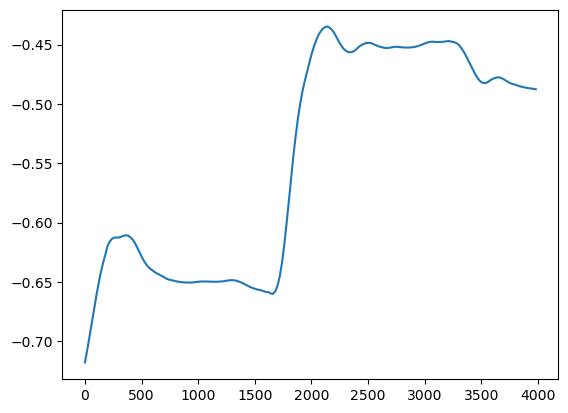

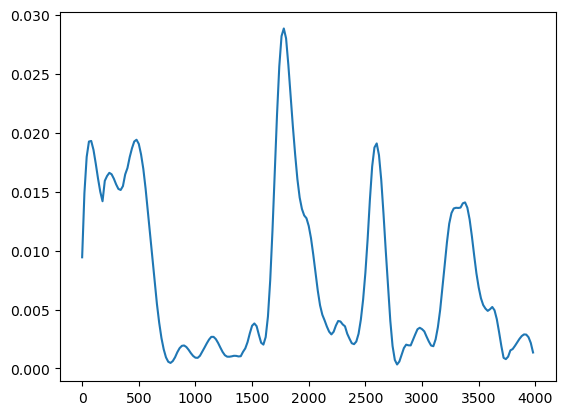

In [12]:
# in cols, get rid of Y_. X_, Z_
def derive_speed_smooth(cols, sample):
    # replace Y_ with nothing, but only if there is no string before Y
    speedcols = [col.replace('Y_', '') for col in cols]
    speedcols = [col.replace('PINKF', 'PINKY_F') for col in speedcols]
    speedcols = [col.replace('X_', '') for col in speedcols]
    # replace INDE with INDEX_
    speedcols = [col.replace('INDEF', 'INDEX_F') for col in speedcols]
    speedcols = [col.replace('Z_', '') for col in speedcols]

    print(speedcols)
    # keep only unique values
    speedcols = list(set(speedcols))

    for col in speedcols:
        x = sample['X_' + col]
        y = sample['Y_' + col]
        z = sample['Z_' + col]

        # calculate speed
        sample[col + '_speed'] = np.insert(np.sqrt(np.diff(x) ** 2 + np.diff(y) ** 2 + np.diff(z) ** 2), 0, 0)
        # absolutize
        sample[col + '_speed'] = np.abs(sample[col + '_speed'])
    
    # smooth speed
    for col in speedcols:
        sample[col + '_speed'] = scipy.signal.savgol_filter(sample[col + '_speed'], 20, 4)
    # OR
    #sample[col + '_speed'] = scipy.signal.savgol_filter(sample[col + '_speed'], 30, 3)
    return(sample)


hand_cols = sample.columns
# get rid of time and fileID
hand_cols = hand_cols.drop(['time', 'fileID']) # 'fileID'

sample = derive_speed_smooth(hand_cols, sample)

# plot RIGHT_WRIST_speed
plt.plot(sample['time'], sample['Y_RIGHT_WRIST'])
plt.show()
plt.plot(sample['time'], sample['RIGHT_WRIST_speed'])
plt.show()

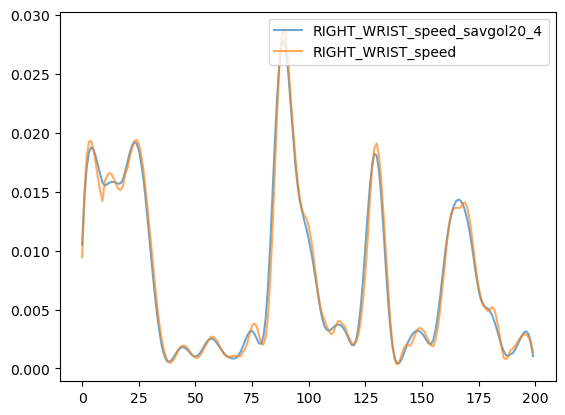

In [14]:
# test smoothing parameters for speed

import scipy
import matplotlib.pyplot as plt
x = 'RIGHT_WRIST_speed'


# list possible window
window = [20]
# list possible orders
order = [4]

# col of interest
samplecol = [x]

# iterate over handcols and apply all possible combinations of window and order, save it to new df
# prepare new df
df_smooth = pd.DataFrame()

for col in samplecol:
    for win in window:
        for ord in order:
            df_smooth[col + '_savgol' + str(win) + '_' + str(ord)] = scipy.signal.savgol_filter(sample[col], win, ord)


# make R_Hand_x from df_sample a list
LKnee_x = sample[x].tolist()
#LKnee_y = sample[y].tolist()
#LKnee_z = sample[z].tolist()


# load these values into df_smooth as a new column
df_smooth[x] = LKnee_x
##df_smooth[y] = LKnee_y
#df_smooth[z] = LKnee_z

#plot all R_Hand_x columns in one plot
colstoplot = [col for col in df_smooth.columns if x in col]
for col in colstoplot:
    plt.plot(df_smooth[col], label=col, alpha=0.65)
plt.legend()
# make only timewindow 50 to 250
#plt.xlim(100, 200)
plt.show()

## Derive vertical velocity and smooth

C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_26568\1902467996.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sample[col + '_velocity'] = np.insert(np.diff(sample[col]), 0, 0)
C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_26568\1902467996.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sample[col + '_velocity'] = np.insert(np.diff(sample[col]), 0, 0)
C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_26568\1902467996.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calli

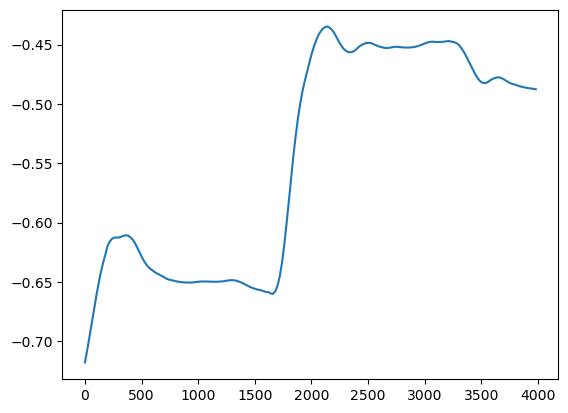

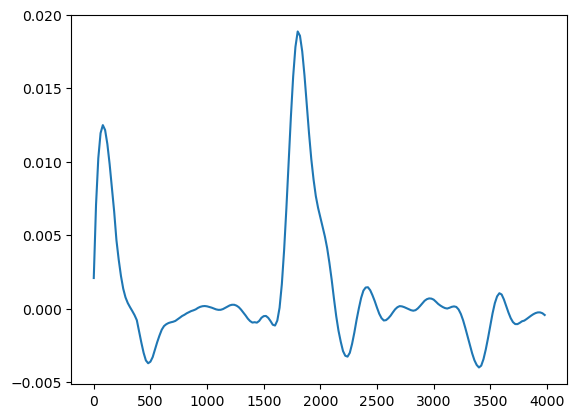

In [15]:
# Get a list of the columns that contain Y_
def derive_vertical_vel_smooth(sample):
    verticalcols = [col for col in sample.columns if 'Y_' in col]
    verticalcols = [col for col in verticalcols if 'speed' not in col] 

# calculate the velocity
    for col in verticalcols:
        sample[col + '_velocity'] = np.insert(np.diff(sample[col]), 0, 0)  
    vel_cols = [col for col in sample.columns if "_velocity" in col]
    for col in vel_cols:
        sample[col] = scipy.signal.savgol_filter(sample[col], 20, 4)
    return sample

sample = derive_vertical_vel_smooth(sample)

plt.plot(sample['time'], sample['Y_RIGHT_WRIST'])
plt.show()
plt.plot(sample['time'], sample['Y_RIGHT_WRIST_velocity'])
plt.show()

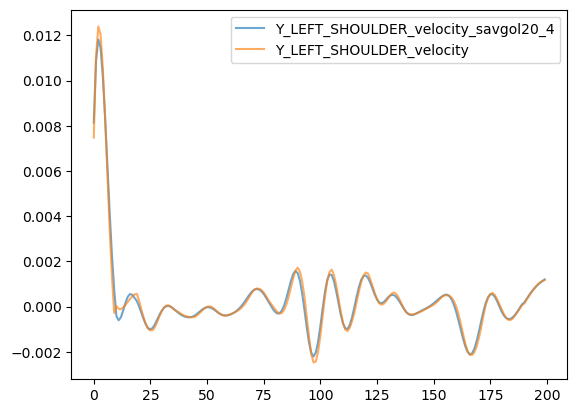

In [16]:
# test possible smoothing windows

import scipy
import matplotlib.pyplot as plt
x = 'Y_LEFT_SHOULDER_velocity'


# list possible window
window = [20]
# list possible orders
order = [4]

# col of interest
samplecol = [x]

# iterate over handcols and apply all possible combinations of window and order, save it to new df
# prepare new df
df_smooth = pd.DataFrame()

for col in samplecol:
    for win in window:
        for ord in order:
            df_smooth[col + '_savgol' + str(win) + '_' + str(ord)] = scipy.signal.savgol_filter(sample[col], win, ord)


# make R_Hand_x from df_sample a list
LKnee_x = sample[x].tolist()
#LKnee_y = sample[y].tolist()
#LKnee_z = sample[z].tolist()


# load these values into df_smooth as a new column
df_smooth[x] = LKnee_x
##df_smooth[y] = LKnee_y
#df_smooth[z] = LKnee_z

#plot all R_Hand_x columns in one plot
colstoplot = [col for col in df_smooth.columns if x in col]
for col in colstoplot:
    plt.plot(df_smooth[col], label=col, alpha=0.65)
plt.legend()
# make only timewindow 50 to 250
#plt.xlim(100, 200)
plt.show()

## Derive Acceleration and Smooth

C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_26568\1318526238.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sample[newcolname] = np.insert(np.diff(sample[col]), 0, 0)
C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_26568\1318526238.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sample[newcolname] = np.insert(np.diff(sample[col]), 0, 0)
C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_26568\1318526238.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.inse

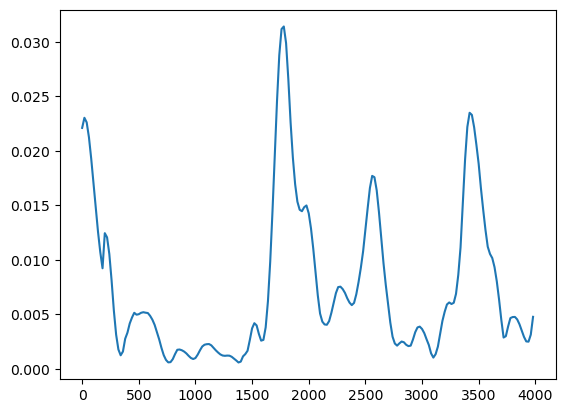

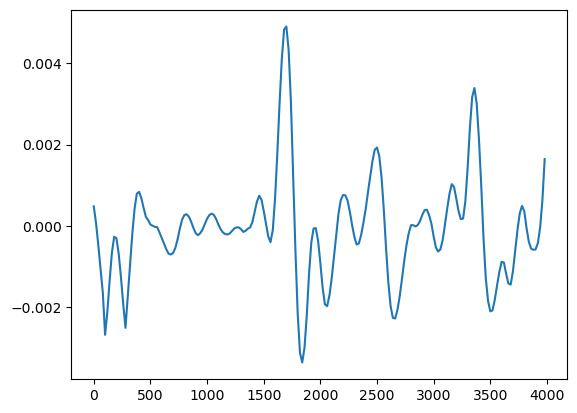

In [17]:
# calculate the acceleration
def derive_accel_smooth(speedcols, sample):
    for col in speedcols:
        newcolname = col.replace('speed', 'acceleration')
        sample[newcolname] = np.insert(np.diff(sample[col]), 0, 0) 
    accel_cols = [col for col in sample.columns if "_acceleration" in col]
    for col in accel_cols:
        sample[col] = scipy.signal.savgol_filter(sample[col], 10, 3)
    return (sample)

speedcols = [col for col in sample.columns if 'speed' in col]
sample = derive_accel_smooth(speedcols, sample)

plt.plot(sample['time'], sample['LEFT_WRIST_speed'])
plt.show()
plt.plot(sample['time'], sample['LEFT_WRIST_acceleration'])
plt.show()
    

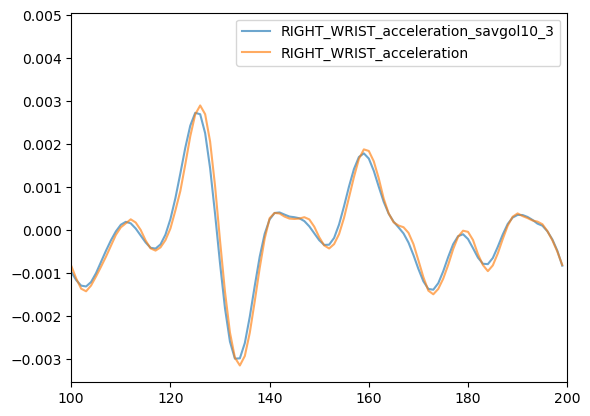

In [19]:
# test possible smoothing windows

import scipy
import matplotlib.pyplot as plt
x = 'RIGHT_WRIST_acceleration'


# list possible window
window = [10]
# list possible orders
order = [3]

# col of interest
samplecol = [x]

# iterate over handcols and apply all possible combinations of window and order, save it to new df
# prepare new df
df_smooth = pd.DataFrame()

for col in samplecol:
    for win in window:
        for ord in order:
            df_smooth[col + '_savgol' + str(win) + '_' + str(ord)] = scipy.signal.savgol_filter(sample[col], win, ord)


# make R_Hand_x from df_sample a list
LKnee_x = sample[x].tolist()
#LKnee_y = sample[y].tolist()
#LKnee_z = sample[z].tolist()


# load these values into df_smooth as a new column
df_smooth[x] = LKnee_x
##df_smooth[y] = LKnee_y
#df_smooth[z] = LKnee_z

#plot all R_Hand_x columns in one plot
colstoplot = [col for col in df_smooth.columns if x in col]
for col in colstoplot:
    plt.plot(df_smooth[col], label=col, alpha=0.65)
plt.legend()
# make only timewindow 50 to 250
plt.xlim(100, 200)
plt.show()

## Derive Jerk and Smooth

C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_26568\3491995224.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sample[newcolname] = np.insert(np.diff(sample[col]), 0, 0)
C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_26568\3491995224.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sample[newcolname] = np.insert(np.diff(sample[col]), 0, 0)
C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_26568\3491995224.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.inse

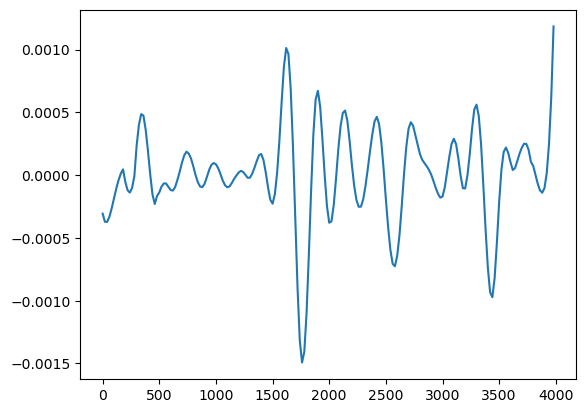

In [20]:
# derive jerk from acceleration 
def derive_jerk_smooth(verticalcols, sample):
    # calcuates the jerk for each vertical column
    for col in accols:
        newcolname = col.replace('acceleration', 'jerk')
        sample[newcolname] = np.insert(np.diff(sample[col]), 0, 0)
    # gets a list of all jerk columns
    jerk_cols = [col for col in sample.columns if "_jerk" in col]
    # smooths all jerk columns
    for col in jerk_cols:
        sample[col] = scipy.signal.savgol_filter(sample[col], 20, 4)
    return (sample)

accols = [col for col in sample.columns if 'acceleration' in col]
sample = derive_jerk_smooth(accols, sample)
plt.plot(sample['time'], sample['LEFT_WRIST_jerk'])
plt.show()


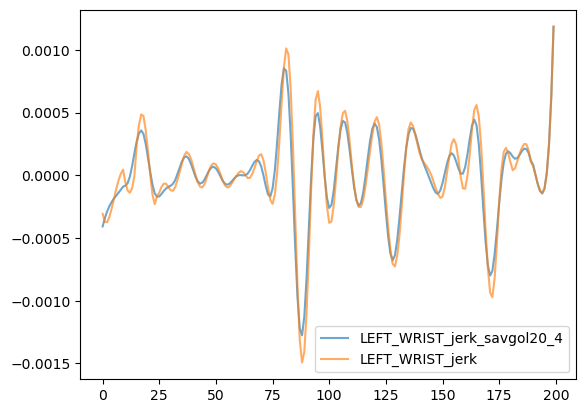

In [21]:
# test possible smoothing windows

import scipy
import matplotlib.pyplot as plt
x = 'LEFT_WRIST_jerk'


# list possible window
window = [20]
# list possible orders
order = [4]

# col of interest
samplecol = [x]

# iterate over handcols and apply all possible combinations of window and order, save it to new df
# prepare new df
df_smooth = pd.DataFrame()

for col in samplecol:
    for win in window:
        for ord in order:
            df_smooth[col + '_savgol' + str(win) + '_' + str(ord)] = scipy.signal.savgol_filter(sample[col], win, ord)


# make R_Hand_x from df_sample a list
LKnee_x = sample[x].tolist()
#LKnee_y = sample[y].tolist()
#LKnee_z = sample[z].tolist()


# load these values into df_smooth as a new column
df_smooth[x] = LKnee_x
##df_smooth[y] = LKnee_y
#df_smooth[z] = LKnee_z

#plot all R_Hand_x columns in one plot
colstoplot = [col for col in df_smooth.columns if x in col]
for col in colstoplot:
    plt.plot(df_smooth[col], label=col, alpha=0.65)
plt.legend()
# make only timewindow 50 to 250
#plt.xlim(100, 200)
plt.show()

## Plotting all the derivations

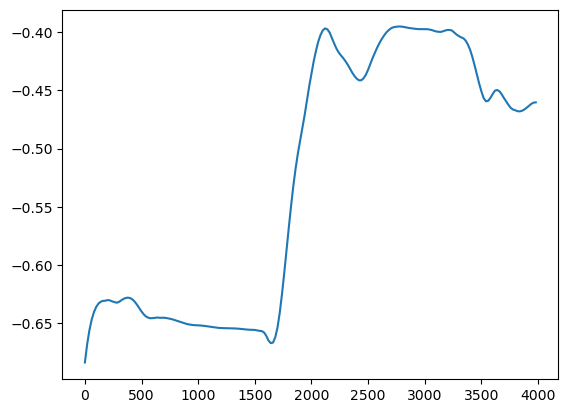

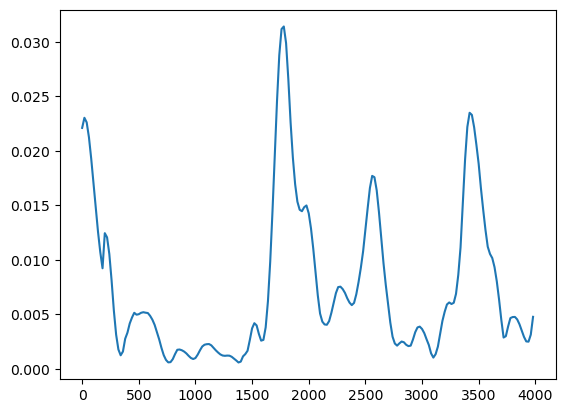

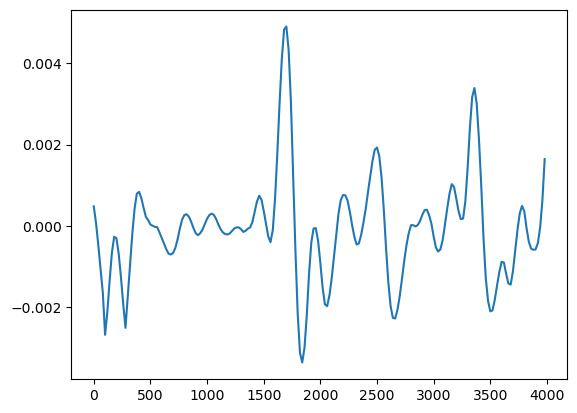

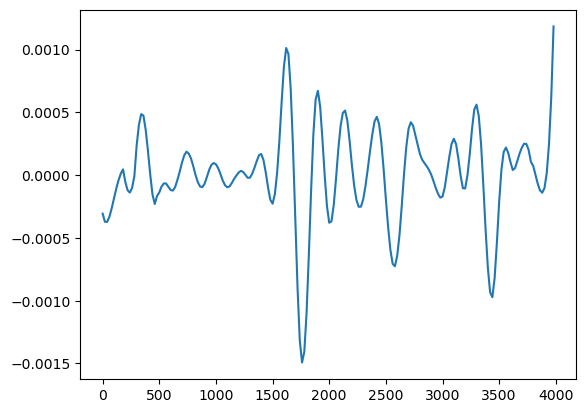

In [22]:

plt.plot(sample['time'], sample['Y_LEFT_WRIST'])
plt.show()
plt.plot(sample['time'], sample['LEFT_WRIST_speed'])
plt.show()
plt.plot(sample['time'], sample['LEFT_WRIST_acceleration'])
plt.show()
plt.plot(sample['time'], sample['LEFT_WRIST_jerk'])
plt.show()

# Functions needed

In [3]:
def clean_data(file):
    sample = pd.read_csv(file)
    sample
    fileID = os.path.basename(file)
    print(fileID)

    # replace _body.csv with ''
    fileID = fileID.replace('.mp4', '')
    fileID = fileID.replace('.csv', '')

    # add fileID column to the sample
    sample['fileID'] = fileID

    # in the sample, get rid of all columns that contain visibility
    visibility_columns = [col for col in sample.columns if 'visibility' in col]

    # get rid of all columns that contain visibility
    sample = sample.drop(visibility_columns, axis=1)

    # for body - lowbody columns
    lowbody = ['FOOT', 'HEEL', 'ANKLE', 'KEE']
    sample = sample.drop([col for col in sample.columns if any(x in col for x in lowbody)], axis=1)


    return sample

# flip the y-axis data (code modified from envisionbox)
def flip_data(df):
    cols = df.columns
    cols  = [col for col in df.columns if 'Y_' in col]
    cols = list(cols)
        # first get the vertical height of the configuration
        # we only do this for the first frame; the transformation will be applied to all frames
    maxpoint = []
    for joint in cols:
        maxpoint.append(df[joint][0])
        # iterate over each joint, in each frame, to flip the y-axis
    for frame in range(len(df)):
        for joint in cols:
            ytrans = max(maxpoint) - df[joint][frame] - 1
            df[joint][frame] = ytrans
 
    return df


# interpolate
def interpolate(sample):
    cols = sample.columns

# put away time and fileID from cols
    cols = cols.drop(['time', 'fileID'])

# loop over the cols and interpolate missing data
    for col in cols:
        sample[col] = sample[col].interpolate(method='linear', x = sample['time'], limit=10)
    return cols, sample

# smooth data
def smooth_data(sample):
    
    if 'body' in sample['fileID'][0]:

        cols_upperbody = ['X_NOSE', 'Y_NOSE', 'Z_NOSE', 'X_LEFT_EYE_INNER', 'Y_LEFT_EYE_INNER', 'Z_LEFT_EYE_INNER', 'X_LEFT_EYE', 'Y_LEFT_EYE', 'Z_LEFT_EYE', 'X_LEFT_EYE_OUTER', 'Y_LEFT_EYE_OUTER', 'Z_LEFT_EYE_OUTER', 'X_RIGHT_EYE_OUTER', 'Y_RIGHT_EYE_OUTER', 'Z_RIGHT_EYE_OUTER', 'X_RIGHT_EYE', 'Y_RIGHT_EYE', 'Z_RIGHT_EYE', 'X_RIGHT_EYE_OUTER.1', 'Y_RIGHT_EYE_OUTER.1', 'Z_RIGHT_EYE_OUTER.1', 'X_LEFT_EAR', 'Y_LEFT_EAR', 'Z_LEFT_EAR', 'X_RIGHT_EAR', 'Y_RIGHT_EAR', 'Z_RIGHT_EAR', 'X_MOUTH_LEFT', 'Y_MOUTH_LEFT', 'Z_MOUTH_LEFT', 'X_MOUTH_RIGHT', 'Y_MOUTH_RIGHT', 'Z_MOUTH_RIGHT', 'X_LEFT_SHOULDER', 'Y_LEFT_SHOULDER', 'Z_LEFT_SHOULDER', 'X_RIGHT_SHOULDER', 'Y_RIGHT_SHOULDER', 'Z_RIGHT_SHOULDER', 'X_LEFT_ELBOW', 'Y_LEFT_ELBOW', 'Z_LEFT_ELBOW', 'X_RIGHT_ELBOW', 'Y_RIGHT_ELBOW', 'Z_RIGHT_ELBOW', 'X_LEFT_WRIST', 'Y_LEFT_WRIST', 'Z_LEFT_WRIST', 'X_RIGHT_WRIST', 'Y_RIGHT_WRIST', 'Z_RIGHT_WRIST', 'X_LEFT_PINKY', 'Y_LEFT_PINKY', 'Z_LEFT_PINKY', 'X_RIGHT_PINKY', 'Y_RIGHT_PINKY', 'Z_RIGHT_PINKY', 'X_LEFT_INDEX', 'Y_LEFT_INDEX', 'Z_LEFT_INDEX', 'X_RIGHT_INDEX', 'Y_RIGHT_INDEX', 'Z_RIGHT_INDEX', 'X_LEFT_THUMB', 'Y_LEFT_THUMB', 'Z_LEFT_THUMB', 'X_RIGHT_THUMB', 'Y_RIGHT_THUMB']
        cols_lowerbody = ['X_LEFT_HIP', 'Y_LEFT_HIP', 'Z_LEFT_HIP', 'X_RIGHT_HIP', 'Y_RIGHT_HIP', 'Z_RIGHT_HIP']

        # smooth upperbody and face with savgol 20,4                            
        for col in cols_upperbody:
            sample[col] = scipy.signal.savgol_filter(sample[col], 20, 4)
        
        # smooth lowerbod with savgol 30,3
        for col in cols_lowerbody:  
            sample[col] = scipy.signal.savgol_filter(sample[col], 10, 1)

    elif 'hands' in sample['fileID'][0]:
        hand_cols = sample.columns
        # get rid of time and fileID
        hand_cols = hand_cols.drop(['time', 'fileID'])
        # smooth hand with savgol 20,4                                             
        for col in hand_cols:
            sample[col] = scipy.signal.savgol_filter(sample[col], 20, 4)
    
    return(sample)


# derive speed
def derive_speed_smooth(cols, sample):
    # replace Y_ with nothing, but only if there is no string before Y
    speedcols = [col.replace('Y_', '') for col in cols]
    speedcols = [col.replace('PINKF', 'PINKY_F') for col in speedcols]
    speedcols = [col.replace('X_', '') for col in speedcols]
    # replace INDE with INDEX_
    speedcols = [col.replace('INDEF', 'INDEX_F') for col in speedcols]
    speedcols = [col.replace('Z_', '') for col in speedcols]

    # keep only unique values
    speedcols = list(set(speedcols))

    for col in speedcols:
        x = sample['X_' + col]
        y = sample['Y_' + col]
        z = sample['Z_' + col]

        # calculate speed
        sample[col + '_speed'] = np.insert(np.sqrt(np.diff(x) ** 2 + np.diff(y) ** 2 + np.diff(z) ** 2), 0, 0)
        # absolutize
        sample[col + '_speed'] = np.abs(sample[col + '_speed'])
    
    # smooth speed
    for col in speedcols:
        sample[col + '_speed'] = scipy.signal.savgol_filter(sample[col + '_speed'], 20, 4)
    # OR
    #sample[col + '_speed'] = scipy.signal.savgol_filter(sample[col + '_speed'], 30, 3)
    return(sample)


# derive vertical velocity
def derive_vertical_vel_smooth(sample):
    verticalcols = [col for col in sample.columns if 'Y_' in col]
    verticalcols = [col for col in verticalcols if 'speed' not in col] 

# calculate the velocity
    for col in verticalcols:
        sample[col + '_velocity'] = np.insert(np.diff(sample[col]), 0, 0)  
    vel_cols = [col for col in sample.columns if "_velocity" in col]
    for col in vel_cols:
        sample[col] = scipy.signal.savgol_filter(sample[col], 20, 4)
    return sample

# derive acceleration
def derive_accel_smooth(speedcols, sample):
    for col in speedcols:
        newcolname = col.replace('speed', 'acceleration')
        sample[newcolname] = np.insert(np.diff(sample[col]), 0, 0) 
    accel_cols = [col for col in sample.columns if "_acceleration" in col]
    for col in accel_cols:
        sample[col] = scipy.signal.savgol_filter(sample[col], 10, 3)
    return (sample)

# derive jerk
def derive_jerk_smooth(verticalcols, sample):
    # calcuates the jerk for each vertical column
    for col in accols:
        newcolname = col.replace('acceleration', 'jerk')
        sample[newcolname] = np.insert(np.diff(sample[col]), 0, 0)
    # gets a list of all jerk columns
    jerk_cols = [col for col in sample.columns if "_jerk" in col]
    # smooths all jerk columns
    for col in jerk_cols:
        sample[col] = scipy.signal.savgol_filter(sample[col], 20, 4)
    return (sample)



# Final code to process body and hand file in Output_TimeSeries

In [8]:
# add progress bar
from tqdm import tqdm

# supress warnings
import warnings
warnings.filterwarnings('ignore')

#get the timeseries files
curfolder = os.getcwd()
print(curfolder)

curfolder = os.getcwd()
print(curfolder)

mtfolder = curfolder + '/Output_TimeSeries/'
print(mtfolder)

processedfolder = curfolder + '/TS_processed/'
vidfolder = curfolder + '/Output_Videos/'

# get all the files in the folder
bodyfiles = glob.glob(mtfolder + '*body_world.csv')
# keep only those tha have GP in the name
bodyfiles = [x for x in bodyfiles if 'GP' in x]
print(bodyfiles)
handfiles = glob.glob(mtfolder + '*hands_world.csv')
# keep only those tha have GP in the name
handfiles = [x for x in handfiles if 'GP' in x]
print(handfiles)
facefiles = glob.glob(mtfolder + '*face_world.csv')

allfiles = bodyfiles + handfiles + facefiles

vidfiles = glob.glob(vidfolder + '*.mp4')
print(vidfiles)

os.makedirs(processedfolder, exist_ok=True)

# create txt file
f = open("error_log.txt", "w")

#for loop to go through every file in the timeseries folder
for file in tqdm (bodyfiles, desc='Processing body files'):
    print('working on', file)
    try:
        sample = clean_data(file)
        fileID = sample['fileID'][0]
        # if you find this file in processed folder, skip it
        if os.path.exists(os.path.join(processedfolder, f'{fileID}.csv')):
            print('already processed')
            continue
    # otherwise continue with the processing
        sample = flip_data(sample)
        cols, sample = interpolate(sample)
        sample = smooth_data(sample)
        sample = derive_speed_smooth(cols, sample)
        sample = derive_vertical_vel_smooth(sample)
        speedcols = [col for col in sample.columns if 'speed' in col]
        sample = derive_accel_smooth(speedcols, sample)
        accols = [col for col in sample.columns if 'acceleration' in col]
        sample = derive_jerk_smooth(accols, sample)
        globals()[fileID] = sample
        globals()[fileID].to_csv(os.path.join(processedfolder, f'{fileID}.csv'), index=False)
    except IndexError:
        print('flipping failed')                   # add text file for error log
        # write to error log
        f.write(f'{fileID} flipping failed\n')
        continue 
    except ValueError:
        print('smoothing failed')                   # add text file for error log
        # write to error log
        f.write(f'{fileID} smoothing failed\n')
        continue
    
#for loop to go through every file in the timeseries folder
for file in tqdm(handfiles, desc='Processing hand files'):
    print('working on', file)
    try:
        sample = clean_data(file)
        fileID = sample['fileID'][0]
        # if you find this file in processed folder, skip it
        if os.path.exists(os.path.join(processedfolder, f'{fileID}.csv')):
            print('already processed')
            continue
    # otherwise continue with the processing
        sample = flip_data(sample)
        sample = flip_data(sample)
        cols, sample = interpolate(sample)
        sample = smooth_data(sample)
        sample = derive_speed_smooth(cols, sample)
        sample = derive_vertical_vel_smooth(sample)
        speedcols = [col for col in sample.columns if 'speed' in col]   
        sample = derive_accel_smooth(speedcols, sample)
        accols = [col for col in sample.columns if 'acceleration' in col]
        sample = derive_jerk_smooth(accols, sample)
        globals()[fileID] = sample
        globals()[fileID].to_csv(os.path.join(processedfolder, f'{fileID}.csv'), index=False)
    except IndexError:
        print('flipping failed')                   # add text file for error log
        # write to error log
        f.write(f'{fileID} flipping failed\n')
        continue 
    except ValueError:
        print('smoothing failed')                   # add text file for error log
        # write to error log
        f.write(f'{fileID} smoothing failed\n')
        continue

f.close()




e:\VICOM_SignGes_Trajectory
e:\VICOM_SignGes_Trajectory
e:\VICOM_SignGes_Trajectory/Output_TimeSeries/
['e:\\VICOM_SignGes_Trajectory/Output_TimeSeries\\GP01_PRUEFUNG.mp4_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/Output_TimeSeries\\GP02_GESCHENK.mp4_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/Output_TimeSeries\\GP03_BETEN.mp4_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/Output_TimeSeries\\GP04_LOBEN.mp4_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/Output_TimeSeries\\GP05_SCHNECKE.mp4_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/Output_TimeSeries\\GP06_FRAU.mp4_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/Output_TimeSeries\\GP08_KOPIEREN.mp4_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/Output_TimeSeries\\GP10_SCHWEIN.mp4_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/Output_TimeSeries\\GP11_GEBEN.mp4_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/Output_TimeSeries\\GP14_ENTSCHEIDEN.mp4_body_world.csv', 'e:\\VICOM_SignGes_Trajectory/Output_TimeSeries\\GP15_INSTAGRAM.mp4

Processing body files:   0%|          | 0/171 [00:00<?, ?it/s]

working on e:\VICOM_SignGes_Trajectory/Output_TimeSeries\GP01_PRUEFUNG.mp4_body_world.csv
GP01_PRUEFUNG.mp4_body_world.csv
already processed
working on e:\VICOM_SignGes_Trajectory/Output_TimeSeries\GP02_GESCHENK.mp4_body_world.csv
GP02_GESCHENK.mp4_body_world.csv
already processed
working on e:\VICOM_SignGes_Trajectory/Output_TimeSeries\GP03_BETEN.mp4_body_world.csv


Processing body files:   2%|▏         | 4/171 [00:00<00:05, 33.28it/s]

GP03_BETEN.mp4_body_world.csv
already processed
working on e:\VICOM_SignGes_Trajectory/Output_TimeSeries\GP04_LOBEN.mp4_body_world.csv
GP04_LOBEN.mp4_body_world.csv
already processed
working on e:\VICOM_SignGes_Trajectory/Output_TimeSeries\GP05_SCHNECKE.mp4_body_world.csv
GP05_SCHNECKE.mp4_body_world.csv
already processed
working on e:\VICOM_SignGes_Trajectory/Output_TimeSeries\GP06_FRAU.mp4_body_world.csv
GP06_FRAU.mp4_body_world.csv
already processed
working on e:\VICOM_SignGes_Trajectory/Output_TimeSeries\GP08_KOPIEREN.mp4_body_world.csv
GP08_KOPIEREN.mp4_body_world.csv
already processed
working on e:\VICOM_SignGes_Trajectory/Output_TimeSeries\GP10_SCHWEIN.mp4_body_world.csv


Processing body files:   5%|▍         | 8/171 [00:00<00:08, 18.77it/s]

... (422 outputs left out)

working on e:\VICOM_SignGes_Trajectory/Output_TimeSeries\GP02_SCHULD.mp4_hands_world.csv
GP02_SCHULD.mp4_hands_world.csv


Processing hand files:  99%|█████████▉| 170/171 [26:17<00:08,  8.84s/it]

working on e:\VICOM_SignGes_Trajectory/Output_TimeSeries\GP02_BEOBACHTEN.mp4_hands_world.csv
GP02_BEOBACHTEN.mp4_hands_world.csv


Processing hand files: 100%|██████████| 171/171 [26:25<00:00,  9.27s/it]


## QUALITY CHECK - the output data in 3d plot

In [40]:
files = glob.glob(processedfolder + '*.csv')
# keep only those tha have GP in the name
files = [x for x in files if 'IP' in x]

sample = pd.read_csv(files[0])

# get the fileID
fileID = os.path.basename(files[0])

# new name
#newname = fileID.replace('body', 'hands')

# find this new file
#sample_h = pd.read_csv(os.path.join(processedfolder, newname))

# get rid of all jerk, velocity, and acceleration columns
sample = sample.drop([col for col in sample.columns if 'jerk' in col], axis=1)
#sample_h = sample_h.drop([col for col in sample_h.columns if 'jerk' in col], axis=1)
sample = sample.drop([col for col in sample.columns if 'velocity' in col], axis=1)
#sample_h = sample_h.drop([col for col in sample_h.columns if 'velocity' in col], axis=1)
sample = sample.drop([col for col in sample.columns if 'acceleration' in col], axis=1)
#sample_h = sample_h.drop([col for col in sample_h.columns if 'acceleration' in col], axis=1)
sample = sample.drop([col for col in sample.columns if 'speed' in col], axis=1)
#sample_h = sample_h.drop([col for col in sample_h.columns if 'speed' in col], axis=1)


# replace PINKY_F with PINKYF
#sample_h.columns = [col.replace('PINKY_F', 'PINKYF') for col in sample_h.columns]
# replace INDEX_F with INDEXF
#sample_h.columns = [col.replace('INDEX_F', 'INDEXF') for col in sample_h.columns]

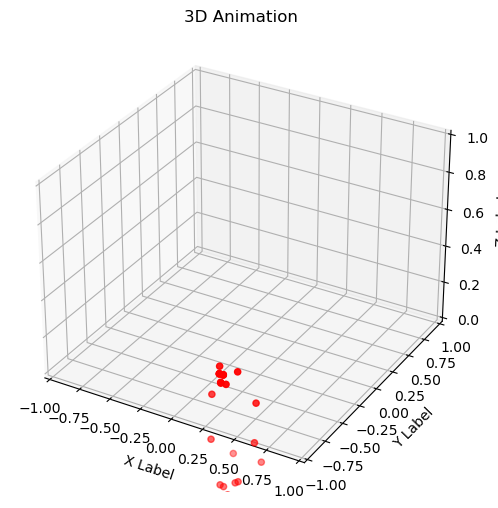

In [42]:
# import pandas as pd
import glob
import os
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.animation import FuncAnimation

# 3D tracking checking
fileexample = sample
#fileexample_hands = sample_h
#print('Well be looking at the following file: ' + fileexample)

MT_tracking = sample
#MT_tracking_hands = sample_h

# Create a figure and axis
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')

# Define the number of frames
num_frames = len(MT_tracking)

# Define the scatter plot
scatter = ax.scatter([], [], [], marker='o')
#scatter2 = ax.scatter([], [], [], marker='o')

# Update function for animation
def update(frame):
    ax.clear()
    ax.set_xlabel('X Label')
    ax.set_ylabel('Y Label')
    ax.set_zlabel('Z Label')
    ax.set_title('3D Animation')
    
    # Set the limits of the axes based on the maximum values
    ax.set_xlim3d(-1, 1)
    ax.set_ylim3d(-1, 1)
    ax.set_zlim3d(0, 1) #we need to flip the vertical
    
    # Plot the data for the current frame
    frame_data = MT_tracking.iloc[frame]
    frame_data_hands = MT_tracking.iloc[frame]
    x = frame_data.filter(like='X_')
    x_hands = frame_data_hands.filter(like='X_')
    y = frame_data.filter(like='Z_')
    y_hands = frame_data_hands.filter(like='Z_')
    z = frame_data.filter(like='Y_')
    z_hands = frame_data_hands.filter(like='Y_')
    # create scatter that has body in blue, and hands in red
    #scatter = ax.scatter(x, y, z, color='blue')
    scatter = ax.scatter(x_hands, y_hands, z_hands, color='red')

    return scatter

# Create the animation
ani = FuncAnimation(fig, update, frames=num_frames, interval=1000/25)

# display the animation
ani.save('3d_animation.mp4', writer='ffmpeg')


## Joint distances

We will now compute the joint angles, operationalized simply as a distance of the neighboring joints. 

We will look at

In the body model:

wrist-shoulder distance      - as a elbow angle
elbow-hip distance           - as a shoulder angle
fingerknuckle-elbow          - as a wrist angle

Also to get some info about the position of the hand movement, we look at

wrist-nose distance
wrist-hip distance


### Distances - body

In [3]:
def getjointdistance(sample, joint1, joint2):

    joint1x = sample['X_' + joint1]
    joint1y = sample['Y_' + joint1]
    joint1z = sample['Z_' + joint1]

    joint2x = sample['X_' + joint2]
    joint2y = sample['Y_' + joint2]
    joint2z = sample['Z_' + joint2]

    # get the x, y, z columns
    x1 = joint1x
    y1 = joint1y
    z1 = joint1z
    x2 = joint2x
    y2 = joint2y
    z2 = joint2z

    # calculate the distance for each dimension separately
    dist_x = x1 - x2
    dist_y = y1 - y2
    dist_z = z1 - z2

    # calculate the total distance
    dist = np.sqrt(dist_x ** 2 + dist_y ** 2 + dist_z ** 2)

    return dist_x, dist_y, dist_z, dist

### Distances - hand

In [4]:
def gethandjointdistance(sample, dictionary, joint1number, joint2number):

    # map the joint number to the joint name, based on the dictionary
    joint1 = dictionary[joint1number]
    joint2 = dictionary[joint2number]

    # left hand
    joint1x_l = sample['X_LEFT_' + joint1]
    joint1y_l = sample['Y_LEFT_' + joint1]
    joint1z_l = sample['Z_LEFT_' + joint1]

    joint2x_l = sample['X_LEFT_' + joint2]
    joint2y_l = sample['Y_LEFT_' + joint2]
    joint2z_l = sample['Z_LEFT_' + joint2]

    # right hand
    joint1x_r = sample['X_RIGHT_' + joint1]
    joint1y_r = sample['Y_RIGHT_' + joint1]
    joint1z_r = sample['Z_RIGHT_' + joint1]

    joint2x_r = sample['X_RIGHT_' + joint2]
    joint2y_r = sample['Y_RIGHT_' + joint2]
    joint2z_r = sample['Z_RIGHT_' + joint2]

    # get the x, y, z columns for both hands
    x1_l = joint1x_l
    y1_l = joint1y_l
    z1_l = joint1z_l
    x2_l = joint2x_l
    y2_l = joint2y_l
    z2_l = joint2z_l   

    x1_r = joint1x_r
    y1_r = joint1y_r
    z1_r = joint1z_r
    x2_r = joint2x_r
    y2_r = joint2y_r
    z2_r = joint2z_r 


    # calculate the distance for each dimension separately
    dist_x_l = x1_l - x2_l
    dist_y_l = y1_l - y2_l
    dist_z_l = z1_l - z2_l

    dist_x_r = x1_r - x2_r
    dist_y_r = y1_r - y2_r
    dist_z_r = z1_r - z2_r

    # calculate the total distance
    dist_l = np.sqrt(dist_x_l ** 2 + dist_y_l ** 2 + dist_z_l ** 2)
    dist_r = np.sqrt(dist_x_r ** 2 + dist_y_r ** 2 + dist_z_r ** 2)

    return dist_x_l, dist_y_l, dist_z_l, dist_l, dist_x_r, dist_y_r, dist_z_r, dist_r

### Derive speed, etc.

In [5]:
# for each column that doesn't have _x, _y, _z, calculate speed, acceleration, and jerk

def derive_speed_accel_jerk(df):
    cols = df.columns
    cols = cols.drop(['time', 'fileID'])
    for col in cols:
        if '_x' not in col and '_y' not in col and '_z' not in col:
            # calculate speed
            df[col + '_speed'] = np.insert(np.diff(df[col]), 0, 0)
            # absolutize
            df[col + '_speed'] = np.abs(df[col + '_speed'])
            # smooth it
            df[col + '_speed'] = scipy.signal.savgol_filter(df[col + '_speed'], 15, 3)
            # calculate acceleration
            df[col + '_acceleration'] = np.insert(np.diff(df[col + '_speed']), 0, 0)
            # smooth it
            df[col + '_acceleration'] = scipy.signal.savgol_filter(df[col + '_acceleration'], 15, 3)
            # calculate jerk
            df[col + '_jerk'] = np.insert(np.diff(df[col + '_acceleration']), 0, 0)
            # smooth it
            df[col + '_jerk'] = scipy.signal.savgol_filter(df[col + '_jerk'], 15, 3)
    return df

### Loop and get distances - body

In [6]:
distances = {}
df_all = pd.DataFrame()
bodyfiles = glob.glob(processedfolder + '*body_world*.csv')
# keep only those tha have GP in the name
bodyfiles = [x for x in bodyfiles if 'LP' in x or 'IP' in x and 'GtST' not in x]

for file in bodyfiles:
    print(file)
    df = pd.read_csv(file)
    try:
        fileID = df['fileID'][0]
    except KeyError:
        continue

    # get rid of all speed, velocity, acceleration, and jerk columns
    df = df.drop([col for col in df.columns if 'speed' in col], axis=1)
    df = df.drop([col for col in df.columns if 'velocity' in col], axis=1)
    df = df.drop([col for col in df.columns if 'acceleration' in col], axis=1)
    df = df.drop([col for col in df.columns if 'jerk' in col], axis=1)

    # get left wrist-shoulder distance in each dimension
    Lwri_sho_x, Lwri_sho_y, Lwri_sho_z, Lwri_sho = getjointdistance(df, 'LEFT_WRIST', 'LEFT_SHOULDER')
    # get right wrist-shoulder distance in each dimension
    Rwri_sho_x, Rwri_sho_y, Rwri_sho_z, Rwri_sho = getjointdistance(df, 'RIGHT_WRIST', 'RIGHT_SHOULDER')
    # get left elbow-hip distance in each dimension
    Lelb_hip_x, Lelb_hip_y, Lelb_hip_z, Lelb_hip = getjointdistance(df, 'LEFT_ELBOW', 'LEFT_HIP')
    # get right elbow-hip distance in each dimension
    Relb_hip_x, Relb_hip_y, Relb_hip_z, Relb_hip = getjointdistance(df, 'RIGHT_ELBOW', 'RIGHT_HIP')
    # get leftknuckle-elbow distance in each dimension
    Lkn_elb_x, Lkn_elb_y, Lkn_elb_z, Lkn_elb = getjointdistance(df, 'LEFT_INDEX', 'LEFT_ELBOW')
    # get rightknuckle-elbow distance in each dimension
    Rkn_elb_x, Rkn_elb_y, Rkn_elb_z, Rkn_elb = getjointdistance(df, 'RIGHT_INDEX', 'RIGHT_ELBOW')
    # get left wrist-nose distance in each dimension
    Lwri_nose_x, Lwri_nose_y, Lwri_nose_z, Lwri_nose = getjointdistance(df, 'LEFT_WRIST', 'NOSE')
    # get right wrist-nose distance in each dimension
    Rwri_nose_x, Rwri_nose_y, Rwri_nose_z, Rwri_nose = getjointdistance(df, 'RIGHT_WRIST', 'NOSE')
    # get left wrist-hip distance in each dimension
    Lwri_hip_x, Lwri_hip_y, Lwri_hip_z, Lwri_hip = getjointdistance(df, 'LEFT_WRIST', 'LEFT_HIP')
    # get right wrist-hip distance in each dimension
    Rwri_hip_x, Rwri_hip_y, Rwri_hip_z, Rwri_hip = getjointdistance(df, 'RIGHT_WRIST', 'RIGHT_HIP')
    
    # save all variables into a dictionary
    distances[fileID] = {'Lwri_sho_x': Lwri_sho_x, 'Lwri_sho_y': Lwri_sho_y, 'Lwri_sho_z': Lwri_sho_z, 'Lwri_sho': Lwri_sho, 
                         'Rwri_sho_x': Rwri_sho_x, 'Rwri_sho_y': Rwri_sho_y, 'Rwri_sho_z': Rwri_sho_z, 'Rwri_sho': Rwri_sho,
                         'Lelb_hip_x': Lelb_hip_x, 'Lelb_hip_y': Lelb_hip_y, 'Lelb_hip_z': Lelb_hip_z, 'Lelb_hip': Lelb_hip,
                         'Relb_hip_x': Relb_hip_x, 'Relb_hip_y': Relb_hip_y, 'Relb_hip_z': Relb_hip_z, 'Relb_hip': Relb_hip,
                         'Lkn_elb_x': Lkn_elb_x, 'Lkn_elb_y': Lkn_elb_y, 'Lkn_elb_z': Lkn_elb_z, 'Lkn_elb': Lkn_elb,
                         'Rkn_elb_x': Rkn_elb_x, 'Rkn_elb_y': Rkn_elb_y, 'Rkn_elb_z': Rkn_elb_z, 'Rkn_elb': Rkn_elb,
                         'Lwri_nose_x': Lwri_nose_x, 'Lwri_nose_y': Lwri_nose_y, 'Lwri_nose_z': Lwri_nose_z, 'Lwri_nose': Lwri_nose,
                         'Rwri_nose_x': Rwri_nose_x, 'Rwri_nose_y': Rwri_nose_y, 'Rwri_nose_z': Rwri_nose_z, 'Rwri_nose': Rwri_nose,
                         'Lwri_hip_x': Lwri_hip_x, 'Lwri_hip_y': Lwri_hip_y, 'Lwri_hip_z': Lwri_hip_z, 'Lwri_hip': Lwri_hip, 
                         'Rwri_hip_x': Rwri_hip_x, 'Rwri_hip_y': Rwri_hip_y, 'Rwri_hip_z': Rwri_hip_z, 'Rwri_hip': Rwri_hip}
    
    distances_df = pd.DataFrame(distances[fileID])
    distances_df['time'] = df['time']
    distances_df['fileID'] = fileID

    # absolutize all numerical columns
    for col in distances_df.columns:
        if 'time' not in col and 'fileID' not in col:
            distances_df[col] = np.abs(distances_df[col])

    # derive speed, acceleration, and jerk for all columns
    distances_df = derive_speed_accel_jerk(distances_df)

    df_all = pd.concat([df_all, distances_df])



/Users/door/Desktop/GtST_FLESH_KinTrajectory/MotionTracking/TS_processed/LP29_01_BODEN_body_world.csv
/Users/door/Desktop/GtST_FLESH_KinTrajectory/MotionTracking/TS_processed/LP34_01_HEBEN_body_world.csv
/Users/door/Desktop/GtST_FLESH_KinTrajectory/MotionTracking/TS_processed/LP07_01_BASKETBALL_body_world.csv
/Users/door/Desktop/GtST_FLESH_KinTrajectory/MotionTracking/TS_processed/LP07_01_BEZAHLEN_body_world.csv
/Users/door/Desktop/GtST_FLESH_KinTrajectory/MotionTracking/TS_processed/LP28_01_KOPIEREN_body_world.csv
/Users/door/Desktop/GtST_FLESH_KinTrajectory/MotionTracking/TS_processed/LP13_02_BRIEF_body_world.csv
/Users/door/Desktop/GtST_FLESH_KinTrajectory/MotionTracking/TS_processed/LP13_02_ZERREISSEN_body_world.csv
/Users/door/Desktop/GtST_FLESH_KinTrajectory/MotionTracking/TS_processed/LP15_01_UNTERTITEL_body_world.csv
/Users/door/Desktop/GtST_FLESH_KinTrajectory/MotionTracking/TS_processed/LP41_01_BUCH_body_world.csv
/Users/door/Desktop/GtST_FLESH_KinTrajectory/MotionTracking/TS

### Loop and get distances - hand


We will follow mediapipe annotation of hand and used the numbers

**here is the picture**
![hand_landmarks_mediapipe.png](attachment:hand_landmarks_mediapipe.png)

In [24]:
import warnings
warnings.filterwarnings('ignore')

hand_distances = {}
df_all = pd.DataFrame()
handfiles = glob.glob(processedfolder + '*hands_world*.csv')
# keep only those tha have GP in the name
#handfiles = [x for x in handfiles if 'GtST' in x]

print(handfiles)

# create dictionary to map hand keypoint to a number
handkeypoints_mp = {'WRIST': 0, 'THUMB_CMC': 1, 'THUMB_MCP': 2, 'THUMB_IP': 3, 'THUMB_TIP': 4,
                 'INDEX_FINGER_MCP': 5, 'INDEX_FINGER_PIP': 6, 'INDEX_FINGER_DIP': 7, 'INDEX_FINGER_TIP': 8,
                 'MIDDLE_FINGER_MCP': 9, 'MIDDLE_FINGER_PIP': 10, 'MIDDLE_FINGER_DIP': 11, 'MIDDLE_FINGER_TIP': 12,
                 'RING_FINGER_MCP': 13, 'RING_FINGER_PIP': 14, 'RING_FINGER_DIP': 15, 'RING_FINGER_TIP': 16,
                 'PINKY_FINGER_MCP': 17, 'PINKY_FINGER_PIP': 18, 'PINKY_FINGER_DIP': 19, 'PINKY_FINGER_TIP': 20}

#make a dictionary that is flipped version of the handkeypoints
handkeypoints = {v: k for k, v in handkeypoints_mp.items()}

for file in handfiles:
    print(file)
    df = pd.read_csv(file)
    try:
        fileID = df['fileID'][0]
    except KeyError:
        continue

    # get rid of all speed, velocity, acceleration, and jerk columns
    df = df.drop([col for col in df.columns if 'speed' in col], axis=1)
    df = df.drop([col for col in df.columns if 'velocity' in col], axis=1)
    df = df.drop([col for col in df.columns if 'acceleration' in col], axis=1)
    df = df.drop([col for col in df.columns if 'jerk' in col], axis=1)

    # get distance between 4-2, 4-1, 3-1, 4-17, 2-0, 3-0, 4-0 by finding the mapping of the keypoint to the number (for each hand)
    l4_2_x, l4_2_y, l4_2_z, l4_2, r4_2_x, r4_2_y, r4_2_z, r4_2 = gethandjointdistance(df, handkeypoints, 4, 2)
    l4_1_x, l4_1_y, l4_1_z, l4_1, r4_1_x, r4_1_y, r4_1_z, r4_1 = gethandjointdistance(df, handkeypoints, 4, 1)
    l3_1_x, l3_1_y, l3_1_z, l3_1, r3_1_x, r3_1_y, r3_1_z, r3_1 = gethandjointdistance(df, handkeypoints, 3, 1)
    l4_17_x, l4_17_y, l4_17_z, l4_17, r4_17_x, r4_17_y, r4_17_z, r4_17 = gethandjointdistance(df, handkeypoints, 4, 17)
    l2_0_x, l2_0_y, l2_0_z, l2_0, r2_0_x, r2_0_y, r2_0_z, r2_0 = gethandjointdistance(df, handkeypoints, 2, 0)
    l3_0_x, l3_0_y, l3_0_z, l3_0, r3_0_x, r3_0_y, r3_0_z, r3_0 = gethandjointdistance(df, handkeypoints, 3, 0)
    l4_0_x, l4_0_y, l4_0_z, l4_0, r4_0_x, r4_0_y, r4_0_z, r4_0 = gethandjointdistance(df, handkeypoints, 4, 0)

    # get distance between 8-6, 7-5, 8-5, 6-0, 7-0, 8-0
    l8_6_x, l8_6_y, l8_6_z, l8_6, r8_6_x, r8_6_y, r8_6_z, r8_6 = gethandjointdistance(df, handkeypoints, 8, 6)
    l7_5_x, l7_5_y, l7_5_z, l7_5, r7_5_x, r7_5_y, r7_5_z, r7_5 = gethandjointdistance(df, handkeypoints, 7, 5)
    l8_5_x, l8_5_y, l8_5_z, l8_5, r8_5_x, r8_5_y, r8_5_z, r8_5 = gethandjointdistance(df, handkeypoints, 8, 5)
    l6_0_x, l6_0_y, l6_0_z, l6_0, r6_0_x, r6_0_y, r6_0_z, r6_0 = gethandjointdistance(df, handkeypoints, 6, 0)
    l7_0_x, l7_0_y, l7_0_z, l7_0, r7_0_x, r7_0_y, r7_0_z, r7_0 = gethandjointdistance(df, handkeypoints, 7, 0)
    l8_0_x, l8_0_y, l8_0_z, l8_0, r8_0_x, r8_0_y, r8_0_z, r8_0 = gethandjointdistance(df, handkeypoints, 8, 0)

    # get distances between 12-10, 11-9, 12-9, 10-0, 11-0, 12-0
    l12_10_x, l12_10_y, l12_10_z, l12_10, r12_10_x, r12_10_y, r12_10_z, r12_10 = gethandjointdistance(df, handkeypoints, 12, 10)
    l11_9_x, l11_9_y, l11_9_z, l11_9, r11_9_x, r11_9_y, r11_9_z, r11_9 = gethandjointdistance(df, handkeypoints, 11, 9)
    l12_9_x, l12_9_y, l12_9_z, l12_9, r12_9_x, r12_9_y, r12_9_z, r12_9 = gethandjointdistance(df, handkeypoints, 12, 9)
    l10_0_x, l10_0_y, l10_0_z, l10_0, r10_0_x, r10_0_y, r10_0_z, r10_0 = gethandjointdistance(df, handkeypoints, 10, 0)
    l11_0_x, l11_0_y, l11_0_z, l11_0, r11_0_x, r11_0_y, r11_0_z, r11_0 = gethandjointdistance(df, handkeypoints, 11, 0)
    l12_0_x, l12_0_y, l12_0_z, l12_0, r12_0_x, r12_0_y, r12_0_z, r12_0 = gethandjointdistance(df, handkeypoints, 12, 0)

    # get distances between 16-14, 15-13, 16-13, 14-0, 15-0, 16-0
    l16_14_x, l16_14_y, l16_14_z, l16_14, r16_14_x, r16_14_y, r16_14_z, r16_14 = gethandjointdistance(df, handkeypoints, 16, 14)
    l15_13_x, l15_13_y, l15_13_z, l15_13, r15_13_x, r15_13_y, r15_13_z, r15_13 = gethandjointdistance(df, handkeypoints, 15, 13)
    l16_13_x, l16_13_y, l16_13_z, l16_13, r16_13_x, r16_13_y, r16_13_z, r16_13 = gethandjointdistance(df, handkeypoints, 16, 13)
    l14_0_x, l14_0_y, l14_0_z, l14_0, r14_0_x, r14_0_y, r14_0_z, r14_0 = gethandjointdistance(df, handkeypoints, 14, 0)
    l15_0_x, l15_0_y, l15_0_z, l15_0, r15_0_x, r15_0_y, r15_0_z, r15_0 = gethandjointdistance(df, handkeypoints, 15, 0)
    l16_0_x, l16_0_y, l16_0_z, l16_0, r16_0_x, r16_0_y, r16_0_z, r16_0 = gethandjointdistance(df, handkeypoints, 16, 0)

    # get distances between 20-18, 19-17, 20-17, 18-0, 19-0, 20-0
    l20_18_x, l20_18_y, l20_18_z, l20_18, r20_18_x, r20_18_y, r20_18_z, r20_18 = gethandjointdistance(df, handkeypoints, 20, 18)
    l19_17_x, l19_17_y, l19_17_z, l19_17, r19_17_x, r19_17_y, r19_17_z, r19_17 = gethandjointdistance(df, handkeypoints, 19, 17)
    l20_17_x, l20_17_y, l20_17_z, l20_17, r20_17_x, r20_17_y, r20_17_z, r20_17 = gethandjointdistance(df, handkeypoints, 20, 17)
    l18_0_x, l18_0_y, l18_0_z, l18_0, r18_0_x, r18_0_y, r18_0_z, r18_0 = gethandjointdistance(df, handkeypoints, 18, 0)
    l19_0_x, l19_0_y, l19_0_z, l19_0, r19_0_x, r19_0_y, r19_0_z, r19_0 = gethandjointdistance(df, handkeypoints, 19, 0)
    l20_0_x, l20_0_y, l20_0_z, l20_0, r20_0_x, r20_0_y, r20_0_z, r20_0 = gethandjointdistance(df, handkeypoints, 20, 0)

    # get distances between fingers - 4-8, 8-12, 12-16, 16-20
    l4_8_x, l4_8_y, l4_8_z, l4_8, r4_8_x, r4_8_y, r4_8_z, r4_8 = gethandjointdistance(df, handkeypoints, 4, 8)
    l8_12_x, l8_12_y, l8_12_z, l8_12, r8_12_x, r8_12_y, r8_12_z, r8_12 = gethandjointdistance(df, handkeypoints, 8, 12)
    l12_16_x, l12_16_y, l12_16_z, l12_16, r12_16_x, r12_16_y, r12_16_z, r12_16 = gethandjointdistance(df, handkeypoints, 12, 16)
    l16_20_x, l16_20_y, l16_20_z, l16_20, r16_20_x, r16_20_y, r16_20_z, r16_20 = gethandjointdistance(df, handkeypoints, 16, 20)

    # save all variables into a dictionary
    hand_distances[fileID] = {'l4_2_x': l4_2_x, 'l4_2_y': l4_2_y, 'l4_2_z': l4_2_z, 'l4_2': l4_2, 'r4_2_x': r4_2_x, 'r4_2_y': r4_2_y, 'r4_2_z': r4_2_z, 'r4_2': r4_2,
                                'l4_1_x': l4_1_x, 'l4_1_y': l4_1_y, 'l4_1_z': l4_1_z, 'l4_1': l4_1, 'r4_1_x': r4_1_x, 'r4_1_y': r4_1_y, 'r4_1_z': r4_1_z, 'r4_1': r4_1,
                                'l3_1_x': l3_1_x, 'l3_1_y': l3_1_y, 'l3_1_z': l3_1_z, 'l3_1': l3_1, 'r3_1_x': r3_1_x, 'r3_1_y': r3_1_y, 'r3_1_z': r3_1_z, 'r3_1': r3_1,
                                'l4_17_x': l4_17_x, 'l4_17_y': l4_17_y, 'l4_17_z': l4_17_z, 'l4_17': l4_17, 'r4_17_x': r4_17_x, 'r4_17_y': r4_17_y, 'r4_17_z': r4_17_z, 'r4_17': r4_17,
                                'l2_0_x': l2_0_x, 'l2_0_y': l2_0_y, 'l2_0_z': l2_0_z, 'l2_0': l2_0, 'r2_0_x': r2_0_x, 'r2_0_y': r2_0_y, 'r2_0_z': r2_0_z, 'r2_0': r2_0,
                                'l3_0_x': l3_0_x, 'l3_0_y': l3_0_y, 'l3_0_z': l3_0_z, 'l3_0': l3_0, 'r3_0_x': r3_0_x, 'r3_0_y': r3_0_y, 'r3_0_z': r3_0_z, 'r3_0': r3_0,
                                'l4_0_x': l4_0_x, 'l4_0_y': l4_0_y, 'l4_0_z': l4_0_z, 'l4_0': l4_0, 'r4_0_x': r4_0_x, 'r4_0_y': r4_0_y, 'r4_0_z': r4_0_z, 'r4_0': r4_0,
                                'l8_6_x': l8_6_x, 'l8_6_y': l8_6_y, 'l8_6_z': l8_6_z, 'l8_6': l8_6, 'r8_6_x': r8_6_x, 'r8_6_y': r8_6_y, 'r8_6_z': r8_6_z, 'r8_6': r8_6,
                                'l7_5_x': l7_5_x, 'l7_5_y': l7_5_y, 'l7_5_z': l7_5_z, 'l7_5': l7_5, 'r7_5_x': r7_5_x, 'r7_5_y': r7_5_y, 'r7_5_z': r7_5_z, 'r7_5': r7_5,
                                'l8_5_x': l8_5_x, 'l8_5_y': l8_5_y, 'l8_5_z': l8_5_z, 'l8_5': l8_5, 'r8_5_x': r8_5_x, 'r8_5_y': r8_5_y, 'r8_5_z': r8_5_z, 'r8_5': r8_5,
                                'l6_0_x': l6_0_x, 'l6_0_y': l6_0_y, 'l6_0_z': l6_0_z, 'l6_0': l6_0, 'r6_0_x': r6_0_x, 'r6_0_y': r6_0_y, 'r6_0_z': r6_0_z, 'r6_0': r6_0,
                                'l7_0_x': l7_0_x, 'l7_0_y': l7_0_y, 'l7_0_z': l7_0_z, 'l7_0': l7_0, 'r7_0_x': r7_0_x, 'r7_0_y': r7_0_y, 'r7_0_z': r7_0_z, 'r7_0': r7_0,
                                'l8_0_x': l8_0_x, 'l8_0_y': l8_0_y, 'l8_0_z': l8_0_z, 'l8_0': l8_0, 'r8_0_x': r8_0_x, 'r8_0_y': r8_0_y, 'r8_0_z': r8_0_z, 'r8_0': r8_0,
                                'l12_10_x': l12_10_x, 'l12_10_y': l12_10_y, 'l12_10_z': l12_10_z, 'l12_10': l12_10, 'r12_10_x': r12_10_x, 'r12_10_y': r12_10_y, 'r12_10_z': r12_10_z, 'r12_10': r12_10,
                                'l11_9_x': l11_9_x, 'l11_9_y': l11_9_y, 'l11_9_z': l11_9_z, 'l11_9': l11_9, 'r11_9_x': r11_9_x, 'r11_9_y': r11_9_y, 'r11_9_z': r11_9_z, 'r11_9': r11_9,
                                'l12_9_x': l12_9_x, 'l12_9_y': l12_9_y, 'l12_9_z': l12_9_z, 'l12_9': l12_9, 'r12_9_x': r12_9_x, 'r12_9_y': r12_9_y, 'r12_9_z': r12_9_z, 'r12_9': r12_9,
                                'l10_0_x': l10_0_x, 'l10_0_y': l10_0_y, 'l10_0_z': l10_0_z, 'l10_0': l10_0, 'r10_0_x': r10_0_x, 'r10_0_y': r10_0_y, 'r10_0_z': r10_0_z, 'r10_0': r10_0,
                                'l11_0_x': l11_0_x, 'l11_0_y': l11_0_y, 'l11_0_z': l11_0_z, 'l11_0': l11_0, 'r11_0_x': r11_0_x, 'r11_0_y': r11_0_y, 'r11_0_z': r11_0_z, 'r11_0': r11_0,
                                'l12_0_x': l12_0_x, 'l12_0_y': l12_0_y, 'l12_0_z': l12_0_z, 'l12_0': l12_0, 'r12_0_x': r12_0_x, 'r12_0_y': r12_0_y, 'r12_0_z': r12_0_z, 'r12_0': r12_0,
                                'l16_14_x': l16_14_x, 'l16_14_y': l16_14_y, 'l16_14_z': l16_14_z, 'l16_14': l16_14, 'r16_14_x': r16_14_x, 'r16_14_y': r16_14_y, 'r16_14_z': r16_14_z, 'r16_14': r16_14,
                                'l15_13_x': l15_13_x, 'l15_13_y': l15_13_y, 'l15_13_z': l15_13_z, 'l15_13': l15_13, 'r15_13_x': r15_13_x, 'r15_13_y': r15_13_y, 'r15_13_z': r15_13_z, 'r15_13': r15_13,
                                'l16_13_x': l16_13_x, 'l16_13_y': l16_13_y, 'l16_13_z': l16_13_z, 'l16_13': l16_13, 'r16_13_x': r16_13_x, 'r16_13_y': r16_13_y, 'r16_13_z': r16_13_z, 'r16_13': r16_13,
                                'l14_0_x': l14_0_x, 'l14_0_y': l14_0_y, 'l14_0_z': l14_0_z, 'l14_0': l14_0, 'r14_0_x': r14_0_x, 'r14_0_y': r14_0_y, 'r14_0_z': r14_0_z, 'r14_0': r14_0,
                                'l15_0_x': l15_0_x, 'l15_0_y': l15_0_y, 'l15_0_z': l15_0_z, 'l15_0': l15_0, 'r15_0_x': r15_0_x, 'r15_0_y': r15_0_y, 'r15_0_z': r15_0_z, 'r15_0': r15_0,
                                'l16_0_x': l16_0_x, 'l16_0_y': l16_0_y, 'l16_0_z': l16_0_z, 'l16_0': l16_0, 'r16_0_x': r16_0_x, 'r16_0_y': r16_0_y, 'r16_0_z': r16_0_z, 'r16_0': r16_0,
                                'l20_18_x': l20_18_x, 'l20_18_y': l20_18_y, 'l20_18_z': l20_18_z, 'l20_18': l20_18, 'r20_18_x': r20_18_x, 'r20_18_y': r20_18_y, 'r20_18_z': r20_18_z, 'r20_18': r20_18,
                                'l19_17_x': l19_17_x, 'l19_17_y': l19_17_y, 'l19_17_z': l19_17_z, 'l19_17': l19_17, 'r19_17_x': r19_17_x, 'r19_17_y': r19_17_y, 'r19_17_z': r19_17_z, 'r19_17': r19_17,
                                'l20_17_x': l20_17_x, 'l20_17_y': l20_17_y, 'l20_17_z': l20_17_z, 'l20_17': l20_17, 'r20_17_x': r20_17_x, 'r20_17_y': r20_17_y, 'r20_17_z': r20_17_z, 'r20_17': r20_17,
                                'l18_0_x': l18_0_x, 'l18_0_y': l18_0_y, 'l18_0_z': l18_0_z, 'l18_0': l18_0, 'r18_0_x': r18_0_x, 'r18_0_y': r18_0_y, 'r18_0_z': r18_0_z, 'r18_0': r18_0,
                                'l19_0_x': l19_0_x, 'l19_0_y': l19_0_y, 'l19_0_z': l19_0_z, 'l19_0': l19_0, 'r19_0_x': r19_0_x, 'r19_0_y': r19_0_y, 'r19_0_z': r19_0_z, 'r19_0': r19_0,
                                'l20_0_x': l20_0_x, 'l20_0_y': l20_0_y, 'l20_0_z': l20_0_z, 'l20_0': l20_0, 'r20_0_x': r20_0_x, 'r20_0_y': r20_0_y, 'r20_0_z': r20_0_z, 'r20_0': r20_0,
                                'l4_8_x': l4_8_x, 'l4_8_y': l4_8_y, 'l4_8_z': l4_8_z, 'l4_8': l4_8, 'r4_8_x': r4_8_x, 'r4_8_y': r4_8_y, 'r4_8_z': r4_8_z, 'r4_8': r4_8,
                                'l8_12_x': l8_12_x, 'l8_12_y': l8_12_y, 'l8_12_z': l8_12_z, 'l8_12': l8_12, 'r8_12_x': r8_12_x, 'r8_12_y': r8_12_y, 'r8_12_z': r8_12_z, 'r8_12': r8_12,
                                'l12_16_x': l12_16_x, 'l12_16_y': l12_16_y, 'l12_16_z': l12_16_z, 'l12_16': l12_16, 'r12_16_x': r12_16_x, 'r12_16_y': r12_16_y, 'r12_16_z': r12_16_z, 'r12_16': r12_16,
                                'l16_20_x': l16_20_x, 'l16_20_y': l16_20_y, 'l16_20_z': l16_20_z, 'l16_20': l16_20, 'r16_20_x': r16_20_x, 'r16_20_y': r16_20_y, 'r16_20_z': r16_20_z, 'r16_20': r16_20}
 
    
    distances_df = pd.DataFrame(hand_distances[fileID])
    distances_df['time'] = df['time']
    distances_df['fileID'] = fileID

    # absolutize all numerical columns
    for col in distances_df.columns:
        if 'time' not in col and 'fileID' not in col:
            distances_df[col] = np.abs(distances_df[col])

    # derive speed, acceleration, and jerk for all columns
    distances_df = derive_speed_accel_jerk(distances_df)

    df_all = pd.concat([df_all, distances_df])

# save df all
df_all.to_csv(os.path.join(curfolder, 'distances_hand_all.csv'), index=False)



['e:\\VICOM_SignGes_Trajectory/TS_processed\\GtST_DGS_ACCORDEON_308_hands_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\GtST_DGS_A-LITTLE_637_hands_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\GtST_DGS_A-LOT_626_hands_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\GtST_DGS_AMBULANCE_480_hands_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\GtST_DGS_ARM_318_hands_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\GtST_DGS_BABY_008_hands_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\GtST_DGS_BASKETBALL_011_hands_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\GtST_DGS_BEARD_331_hands_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\GtST_DGS_BEER_014_hands_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\GtST_DGS_BILLIARD_342_hands_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\GtST_DGS_BIRD_627_hands_world.csv', 'e:\\VICOM_SignGes_Trajectory/TS_processed\\GtST_DGS_BIRTH_016_hands_world.csv', 'e:\\VICOM_Si

KeyboardInterrupt: 

In [19]:
df

,time,X_LEFT_WRIST,Y_LEFT_WRIST,Z_LEFT_WRIST,X_LEFT_THUMB_CMC,Y_LEFT_THUMB_CMC,Z_LEFT_THUMB_CMC,X_LEFT_THUMB_MCP,Y_LEFT_THUMB_MCP,Z_LEFT_THUMB_MCP,...,X_RIGHT_PINKY_FINGER_PIP,Y_RIGHT_PINKY_FINGER_PIP,Z_RIGHT_PINKY_FINGER_PIP,X_RIGHT_PINKY_FINGER_DIP,Y_RIGHT_PINKY_FINGER_DIP,Z_RIGHT_PINKY_FINGER_DIP,X_RIGHT_PINKY_FINGER_TIP,Y_RIGHT_PINKY_FINGER_TIP,Z_RIGHT_PINKY_FINGER_TIP,fileID
0,0.000000,0.517322,-0.903113,4.505828e-08,0.496715,-0.906901,-0.000046,0.481839,-0.917587,0.000131,...,-0.492540,-0.981172,-0.018454,-0.500632,-0.979780,-0.021187,-0.504836,-0.973973,-0.023481,GtST_DGS_TO-PUT-LIPSTICK-ON_489_hands_world
1,33.333333,0.516165,-0.903218,7.335977e-08,0.498584,-0.912775,-0.000122,0.484278,-0.925912,0.000233,...,-0.486819,-1.002502,-0.016843,-0.495900,-1.006996,-0.018412,-0.501618,-1.005814,-0.020412,GtST_DGS_TO-PUT-LIPSTICK-ON_489_hands_world
2,66.666667,0.515457,-0.904437,8.902741e-08,0.499773,-0.916109,-0.000175,0.485845,-0.930490,0.000216,...,-0.485356,-1.011838,-0.015418,-0.494059,-1.018839,-0.016325,-0.499887,-1.019642,-0.018088,GtST_DGS_TO-PUT-LIPSTICK-ON_489_hands_world
3,100.000000,0.515103,-0.906370,9.496557e-08,0.500424,-0.917479,-0.000198,0.486722,-0.932198,0.000134,...,-0.486742,-1.009286,-0.014138,-0.494171,-1.016411,-0.014771,-0.499132,-1.017386,-0.016356,GtST_DGS_TO-PUT-LIPSTICK-ON_489_hands_world
4,133.333333,0.515018,-0.908670,9.376528e-08,0.500666,-0.917400,-0.000188,0.487070,-0.931819,0.000031,...,-0.489761,-0.995202,-0.012972,-0.495430,-1.000939,-0.013615,-0.498917,-1.000989,-0.015083,GtST_DGS_TO-PUT-LIPSTICK-ON_489_hands_world
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,2033.333333,0.512564,-0.917153,7.762651e-08,0.496519,-0.921541,-0.001067,0.480937,-0.934833,-0.000837,...,-0.473989,-1.020543,-0.024660,-0.482676,-1.023037,-0.026365,-0.488590,-1.019993,-0.028120,GtST_DGS_TO-PUT-LIPSTICK-ON_489_hands_world
62,2066.666667,0.512233,-0.917293,8.373235e-08,0.496723,-0.923270,-0.001275,0.481231,-0.937310,-0.001049,...,-0.469396,-1.014087,-0.026648,-0.479520,-1.015895,-0.028062,-0.486230,-1.012331,-0.029614,GtST_DGS_TO-PUT-LIPSTICK-ON_489_hands_world
63,2100.000000,0.512030,-0.918082,7.735046e-08,0.497294,-0.924987,-0.001191,0.482206,-0.939381,-0.000991,...,-0.469354,-1.003483,-0.027843,-0.480027,-1.003810,-0.028964,-0.486758,-0.999100,-0.030294,GtST_DGS_TO-PUT-LIPSTICK-ON_489_hands_world
64,2133.333333,0.512006,-0.919729,5.300965e-08,0.498360,-0.926591,-0.000692,0.484099,-0.940724,-0.000542,...,-0.475644,-0.993581,-0.028031,-0.485560,-0.991294,-0.028856,-0.491256,-0.984495,-0.029944,GtST_DGS_TO-PUT-LIPSTICK-ON_489_hands_world


In [8]:
# save df all
df_all.to_csv(os.path.join(curfolder, 'distances_learners.csv'), index=False)

In [55]:
sample

,Lwri_sho_x,Lwri_sho_y,Lwri_sho_z,Lwri_sho,Rwri_sho_x,Rwri_sho_y,Rwri_sho_z,Rwri_sho,Lelb_hip_x,Lelb_hip_y,...,Lwri_nose_jerk,Rwri_nose_speed,Rwri_nose_acceleration,Rwri_nose_jerk,Lwri_hip_speed,Lwri_hip_acceleration,Lwri_hip_jerk,Rwri_hip_speed,Rwri_hip_acceleration,Rwri_hip_jerk
0,0.013123,0.305303,0.209390,0.370441,0.207228,0.302542,0.111005,0.383142,0.067160,0.180812,...,-0.000062,0.000178,-0.000115,0.000073,0.009151,0.001175,-0.000304,0.005297,0.000853,-0.000036
1,0.011451,0.307785,0.194514,0.364278,0.205149,0.304755,0.109804,0.383430,0.055450,0.178936,...,-0.000098,0.000110,0.000008,0.000050,0.010571,0.000349,-0.000453,0.006765,0.000573,-0.000198
2,0.010621,0.309803,0.185993,0.361502,0.203729,0.306288,0.109661,0.383853,0.046921,0.177545,...,-0.000115,0.000108,0.000080,0.000031,0.010938,-0.000309,-0.000517,0.007482,0.000272,-0.000297
3,0.010431,0.311432,0.182319,0.361025,0.202862,0.307282,0.110239,0.384353,0.040944,0.176529,...,-0.000115,0.000158,0.000111,0.000017,0.010443,-0.000810,-0.000510,0.007569,-0.000032,-0.000341
4,0.010702,0.312740,0.182154,0.362078,0.202449,0.307862,0.111244,0.384889,0.036951,0.175794,...,-0.000103,0.000246,0.000110,0.000006,0.009279,-0.001165,-0.000445,0.007144,-0.000325,-0.000339
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,0.016075,0.335708,0.192352,0.387243,0.187460,0.317879,0.124552,0.389488,0.032120,0.178111,...,0.000059,0.000421,0.000061,0.000083,0.000395,0.000072,0.000101,0.001222,0.000191,0.000265
196,0.015808,0.336124,0.190565,0.386709,0.187622,0.318165,0.121338,0.388785,0.031667,0.178070,...,0.000076,0.000613,0.000178,0.000118,0.000649,0.000226,0.000153,0.001896,0.000604,0.000408
197,0.015765,0.336710,0.188319,0.386117,0.188085,0.318621,0.116660,0.387950,0.030959,0.177895,...,0.000091,0.000960,0.000331,0.000155,0.001124,0.000441,0.000214,0.003167,0.001183,0.000574
198,0.016046,0.337429,0.185779,0.385525,0.188887,0.319248,0.110514,0.387054,0.029929,0.177533,...,0.000103,0.001488,0.000523,0.000193,0.001864,0.000725,0.000283,0.005156,0.001948,0.000764


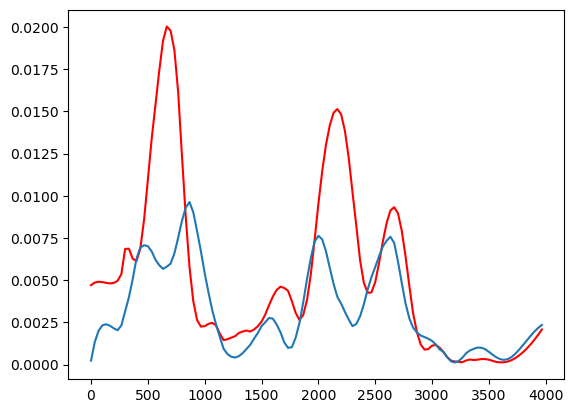

In [9]:
# plot the distance between left wrist and left shoulder

# pick one fileID
sample = distances_df
plt.plot(sample['time'], sample['Rwri_hip_speed'], color='red')
plt.plot(sample['time'], sample['Lwri_hip_speed'])
plt.show()

In [34]:

df_all

,Lwri_sho_x,Lwri_sho_y,Lwri_sho_z,Lwri_sho,Rwri_sho_x,Rwri_sho_y,Rwri_sho_z,Rwri_sho,Lelb_hip_x,Lelb_hip_y,...,Lwri_nose_jerk,Rwri_nose_speed,Rwri_nose_acceleration,Rwri_nose_jerk,Lwri_hip_speed,Lwri_hip_acceleration,Lwri_hip_jerk,Rwri_hip_speed,Rwri_hip_acceleration,Rwri_hip_jerk
0,0.043116,0.368151,0.010016,0.370802,0.306654,0.359416,0.093396,0.481601,0.079220,0.166719,...,-0.000224,0.006953,0.001403,0.000015,0.022619,-0.000410,-0.000597,0.009907,0.001063,-0.000176
1,0.039692,0.373305,0.056873,0.379692,0.288589,0.374129,0.100858,0.483145,0.082573,0.173815,...,-0.000135,0.009616,0.001263,-0.000126,0.020355,-0.001385,-0.000389,0.011483,0.000657,-0.000207
2,0.037244,0.377009,0.092570,0.389990,0.274869,0.382030,0.107100,0.482670,0.085426,0.179049,...,-0.000060,0.011415,0.001057,-0.000225,0.018334,-0.001936,-0.000216,0.012461,0.000360,-0.000210
3,0.035536,0.379568,0.118849,0.399324,0.264354,0.384841,0.112496,0.480251,0.087951,0.182745,...,0.000002,0.012463,0.000803,-0.000285,0.016546,-0.002137,-0.000077,0.012944,0.000159,-0.000193
4,0.034363,0.381251,0.137315,0.406680,0.256027,0.384087,0.117358,0.476283,0.090291,0.185196,...,0.000051,0.012875,0.000516,-0.000312,0.014977,-0.002062,0.000030,0.013032,0.000036,-0.000160
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,0.095608,0.394042,0.166722,0.438414,0.122016,0.424494,0.162499,0.470626,0.067821,0.164520,...,0.000076,0.000738,-0.000010,0.000025,0.000141,-0.000102,0.000297,0.000656,-0.000028,0.000061
196,0.096495,0.393581,0.165858,0.437866,0.122544,0.424381,0.162130,0.470534,0.067170,0.164463,...,0.000071,0.000774,0.000018,0.000031,0.000530,0.000313,0.000418,0.000727,0.000069,0.000082
197,0.096935,0.392953,0.164267,0.436797,0.122948,0.424646,0.160577,0.470346,0.066797,0.164906,...,0.000061,0.000824,0.000045,0.000032,0.001495,0.000875,0.000560,0.000911,0.000185,0.000106
198,0.096605,0.392194,0.161712,0.435085,0.123037,0.425408,0.157672,0.470075,0.067023,0.166197,...,0.000047,0.000884,0.000068,0.000026,0.003140,0.001604,0.000724,0.001229,0.000320,0.000135
